In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sales = pd.read_csv("../data/daily_sales.csv", parse_dates=["date"])
outlets = pd.read_csv("../data/outlets.csv")
tickets = pd.read_csv("../data/tickets_week.csv", parse_dates=["txn_datetime"])
names = outlets.set_index("outlet_id")["outlet_name"].to_dict()
daily = sales.groupby(["date", "outlet_id"], as_index=False).agg(
    revenue=("revenue_sgd", "sum"), tickets=("tickets", "sum")
)
monthly = sales.pivot_table(
    index="date", columns="outlet_id", values="revenue_sgd", aggfunc="sum"
).resample("M").sum()

## pairplot — every pair of columns at once

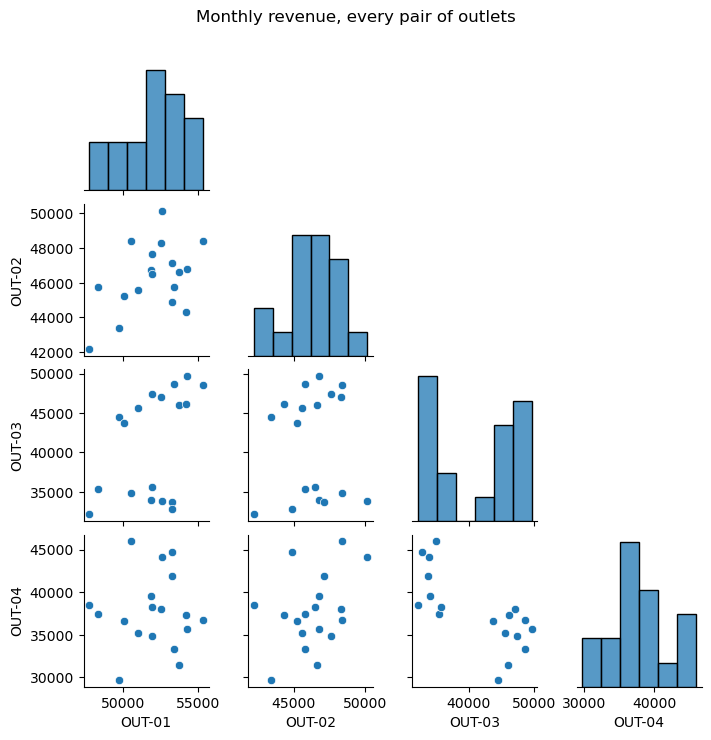

In [2]:
# One panel per pair of columns. `corner=True` drops the redundant mirror half.
g = sns.pairplot(monthly[["OUT-01", "OUT-02", "OUT-03", "OUT-04"]], corner=True, height=1.8)
g.figure.suptitle("Monthly revenue, every pair of outlets", y=1.02)
plt.show()

## jointplot — a scatter with its margins

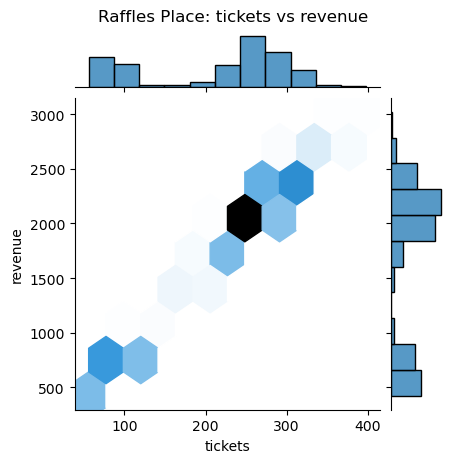

In [3]:
# `kind="hex"` bins the points, which stops overplotting hiding the density.
g = sns.jointplot(data=daily[daily["outlet_id"] == "OUT-01"],
                  x="tickets", y="revenue", kind="hex", height=4.5)
g.figure.suptitle("Raffles Place: tickets vs revenue", y=1.02)
plt.show()

## FacetGrid — small multiples you control by hand

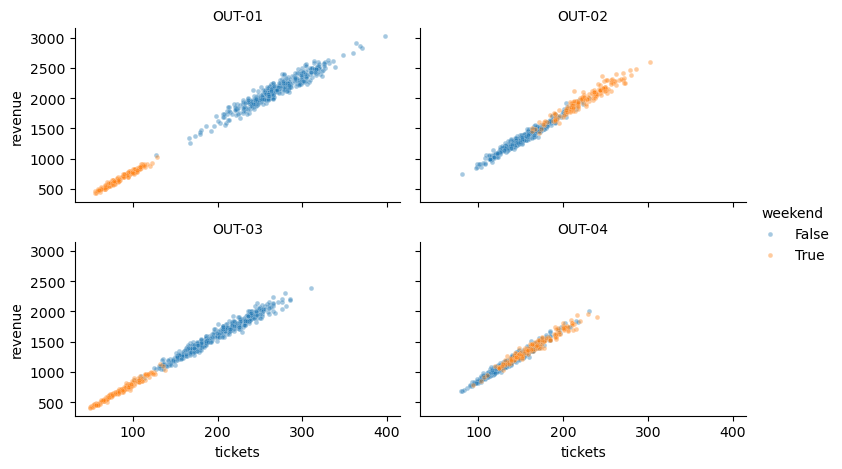

In [4]:
# `relplot`/`catplot` are wrappers over this. Use FacetGrid when you need a custom draw.
d = daily[daily["outlet_id"].isin(["OUT-01", "OUT-02", "OUT-03", "OUT-04"])].copy()
d["weekend"] = d["date"].dt.dayofweek >= 5

g = sns.FacetGrid(d, col="outlet_id", hue="weekend", col_wrap=2, height=2.4, aspect=1.6)
g.map(sns.scatterplot, "tickets", "revenue", alpha=0.4, s=12)
g.add_legend(title="weekend")
g.set_titles("{col_name}")
plt.show()

## Styles, palettes and rcParams

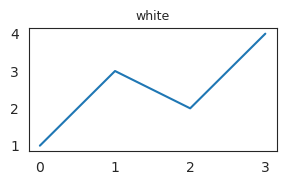

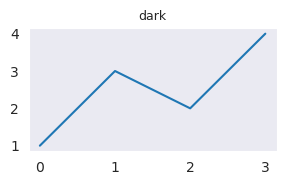

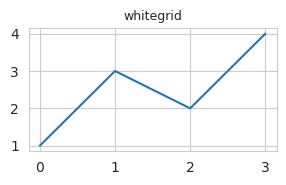

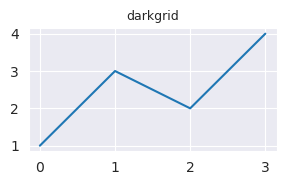

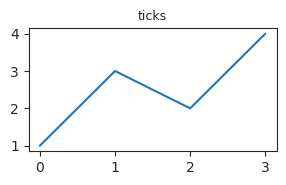

In [5]:
# The five built-in styles, one small chart each. `with sns.axes_style(...)` applies a style
# to just the charts created inside the block, so your global setting is left alone.
for style in ["white", "dark", "whitegrid", "darkgrid", "ticks"]:
    with sns.axes_style(style):
        fig, ax = plt.subplots(figsize=(3.2, 1.6))
        ax.plot([1, 3, 2, 4])
        ax.set_title(style, fontsize=9)
        plt.show()

colorblind   qualitative -- unordered categories


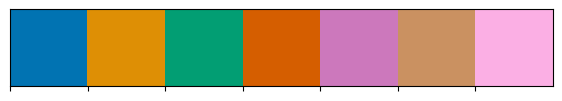

Blues        sequential -- low to high


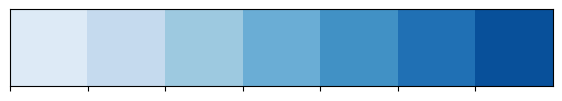

RdBu_r       diverging -- has a meaningful middle


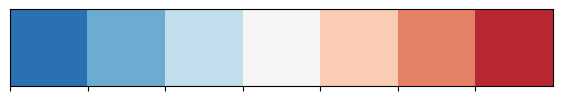

In [6]:
# Palette types, and when each is right.
for name, kind in [("colorblind", "qualitative -- unordered categories"),
                   ("Blues", "sequential -- low to high"),
                   ("RdBu_r", "diverging -- has a meaningful middle")]:
    print(f"{name:<12} {kind}")
    sns.palplot(sns.color_palette(name, 7))
    plt.show()

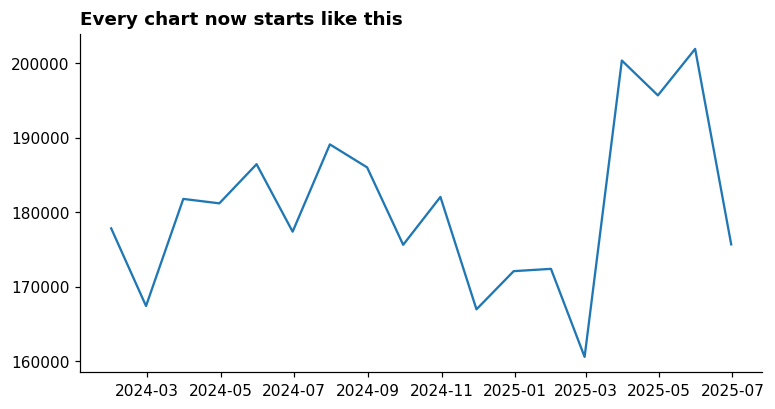

In [7]:
# House style in one place: set it once at the top of a notebook, forget about it.
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "font.size": 10,
    "legend.frameon": False,
})

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.sum(axis=1))
ax.set_title("Every chart now starts like this")
plt.show()

## Saving for screen and for print

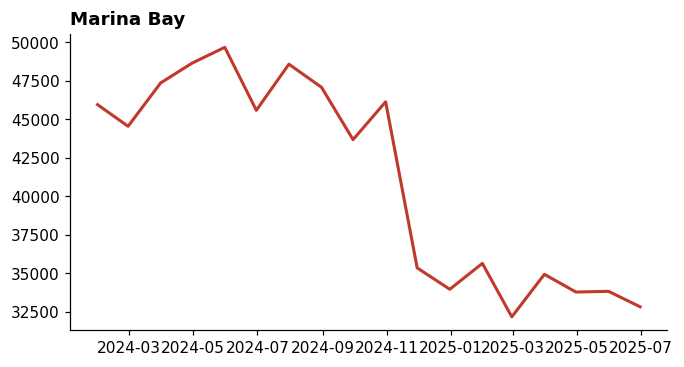

['ref_print.png', 'ref_screen.png', 'ref_vector.svg']


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(monthly.index, monthly["OUT-03"], color="#c0392b", linewidth=2)
ax.set_title("Marina Bay")

import os
os.makedirs("../visualisations", exist_ok=True)

fig.savefig("../visualisations/ref_screen.png", dpi=110, bbox_inches="tight")   # slides, email
fig.savefig("../visualisations/ref_print.png", dpi=300, bbox_inches="tight")    # print
fig.savefig("../visualisations/ref_vector.svg", bbox_inches="tight")            # scales forever
plt.show()

print(sorted(f for f in os.listdir("../visualisations") if f.startswith("ref_")))

## A dual axis, and why to avoid it

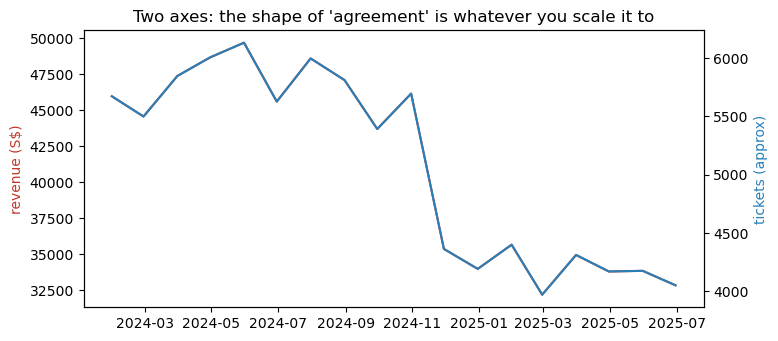

In [4]:
# Two different units on one chart. It works, and it is almost always a bad idea.
fig, ax1 = plt.subplots(figsize=(8, 3.6))
m3 = monthly["OUT-03"]

ax1.plot(m3.index, m3.values, color="#c0392b")
ax1.set_ylabel("revenue (S$)", color="#c0392b")

ax2 = ax1.twinx()                       # 👈 a second y-axis sharing the same x
ax2.plot(m3.index, m3.values / 8.1, color="#2980b9")
ax2.set_ylabel("tickets (approx)", color="#2980b9")

ax1.set_title("Two axes: the shape of 'agreement' is whatever you scale it to")
plt.show()

## Mock Data
Dynamic chart that highlight the falling and improving outlet without a specifc outlet hardcorded

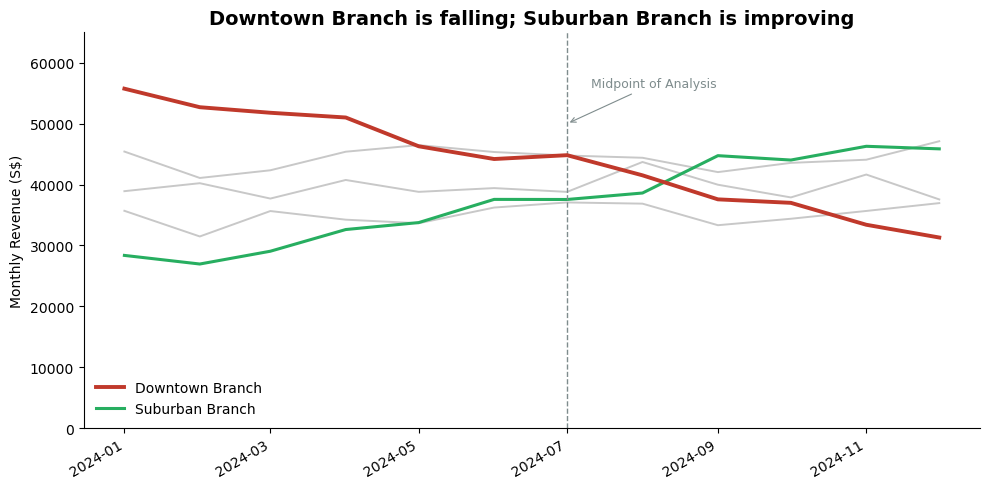

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERATE MOCK SAMPLE DATA
# ==========================================
np.random.seed(42) 
# FIXED: Changed "ME" to "MS" (Month Start)
dates = pd.date_range(start="2024-01-01", periods=12, freq="MS") 

# Create mock data
data = {
    "OUT-01": np.linspace(55000, 32000, 12) + np.random.normal(0, 1500, 12),
    "OUT-02": np.linspace(28000, 48000, 12) + np.random.normal(0, 1500, 12),
    "OUT-03": np.random.normal(40000, 2000, 12),
    "OUT-04": np.random.normal(45000, 2000, 12),
    "OUT-05": np.random.normal(35000, 2000, 12)
}

monthly = pd.DataFrame(data, index=dates)

name_mapping = {
    "OUT-01": "Downtown Branch",
    "OUT-02": "Suburban Branch",
    "OUT-03": "Mall Branch",
    "OUT-04": "Airport Branch",
    "OUT-05": "Street Branch"
}

# ==========================================
# 2. DYNAMIC IDENTIFICATION
# ==========================================
midpoint = len(monthly) // 2
first_half = monthly.iloc[:midpoint]
second_half = monthly.iloc[midpoint:]

mean_first = first_half.mean()
mean_second = second_half.mean()

revenue_drop = mean_first - mean_second
revenue_growth = mean_second - mean_first

falling_outlet = revenue_drop.idxmax()   
improving_outlet = revenue_growth.idxmax() 

# ==========================================
# 3. PLOTTING
# ==========================================
fig, ax = plt.subplots(figsize=(10, 5))

for col in monthly.columns:
    display_name = name_mapping.get(col, col)
    
    if col == falling_outlet:
        ax.plot(monthly.index, monthly[col], color="#c0392b", linewidth=2.8, label=display_name, zorder=3) 
    elif col == improving_outlet:
        ax.plot(monthly.index, monthly[col], color="#27ae60", linewidth=2.2, label=display_name, zorder=2)
    else:
        ax.plot(monthly.index, monthly[col], color="#c8c8c8", linewidth=1.4, zorder=1)

# Add a visual marker in the middle
mid_date = monthly.index[midpoint]
ax.axvline(mid_date, color="#7f8c8d", linestyle="--", linewidth=1)
ax.annotate("Midpoint of Analysis",
            xy=(mid_date, 50000), xytext=(mid_date + pd.Timedelta(days=10), 56000),
            fontsize=9, color="#7f8c8d",
            arrowprops=dict(arrowstyle="->", color="#7f8c8d", linewidth=0.8))

falling_name = name_mapping.get(falling_outlet, falling_outlet)
improving_name = name_mapping.get(improving_outlet, improving_outlet)
ax.set_title(f"{falling_name} is falling; {improving_name} is improving", fontsize=14, weight="bold")

ax.set_ylabel("Monthly Revenue (S$)")
ax.set_ylim(0, 65000)
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False) 

fig.autofmt_xdate() # Rotates the date labels so they don't overlap
plt.tight_layout()
plt.show()